In [2]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [3]:
df = pd.read_csv('../dataset/iris.csv')
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [5]:
# Features Selection
X = df.iloc[:, :-1]  # seluruh kolom numerik (4 fitur)
y = df.iloc[:, -1]   # label (tidak digunakan pada klasterisasi)

print(X.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


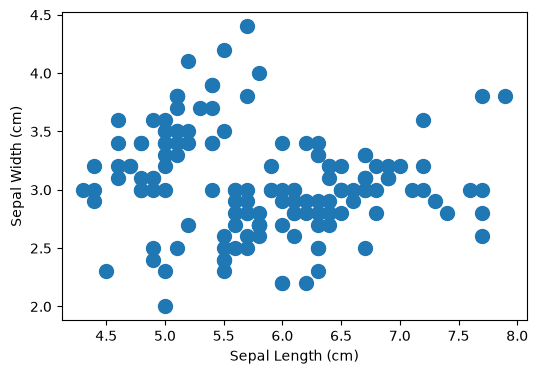

In [6]:
# Scatterplot menggunakan dua fitur pertama
plt.figure(figsize=(6, 4))
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)

In [7]:
# Build a K-Means Model
# Berdasarkan inspeksi visual, diasumsikan terdapat 2 cluster
cl_kmeans = KMeans(n_clusters=2)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X)

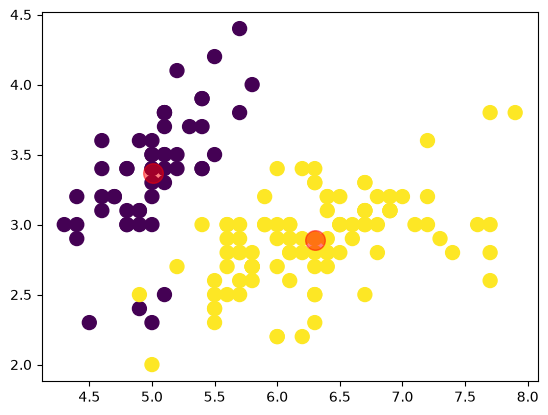

In [13]:
# Plot the clustering result
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans)

# Plot the centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

In [9]:
# Print SSE value
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.3479517603579


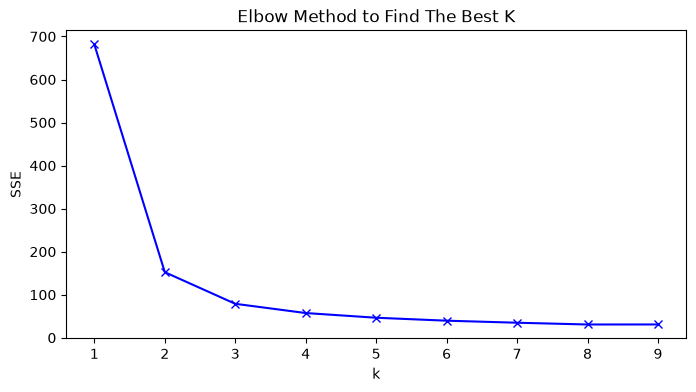

In [14]:
# Find the best k using Elbow Method

# List SSE values
sse = []

# Build k range from 1 to 9
K = range(1, 10)

# Find the SSE value for each k
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

In [11]:
# Tampilkan nilai SSE setiap k
for k, nilai in zip(K, sse):
    print(f'k={k}: SSE={nilai:.3f}')

k=1: SSE=681.371
k=2: SSE=152.348
k=3: SSE=78.851
k=4: SSE=57.228
k=5: SSE=46.461
k=6: SSE=39.040
k=7: SSE=34.306
k=8: SSE=30.132
k=9: SSE=28.291


Berdasarkan grafik, SSE turun sangat tajam dari `k=1` ke `k=2` dan dari `k=2` ke `k=3`, kemudian penurunan melandai secara relatif stabil setelah `k=3`. Posisi "elbow" tersebut menunjukkan bahwa **k=3** adalah jumlah cluster yang paling optimal. Nilai ini juga sesuai dengan karakteristik dataset Iris yang sebenarnya memiliki tiga spesies, meskipun label tidak digunakan dalam pemodelan.